# PS2 - Transfer Learning with MobileNetV2 (Feature Extraction + Fine-Tuning)
Dataset: TensorFlow Flower Photos (5 classes, downloaded automatically).

## 1. Setup and GPU / VRAM check

In [2]:

import pathlib
import subprocess

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow import keras
from tensorflow.keras import layers

IMG = (160, 160)
BATCH = 32
EPOCHS = 5
FINE_EPOCHS = 5
FINE_TUNE_LAYERS = 30
MIN_FREE_VRAM_MB = 2048
SEED = 42

keras.utils.set_random_seed(SEED)


def require_gpu(min_free_mb):
    gpus = tf.config.list_physical_devices("GPU")

    if not gpus:
        print("GPU NOT FOUND - Running on CPU instead.")
        return None

    for gpu in gpus:
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError:
            pass

    free_mb = None

    try:
        out = subprocess.check_output(
            ["nvidia-smi", "--query-gpu=memory.free", "--format=csv,noheader,nounits"],
            text=True,
        )
        free_mb = max(int(v) for v in out.split())
    except Exception:
        print("Note: could not query free VRAM via nvidia-smi; continuing.")

    if free_mb is not None and free_mb < min_free_mb:
        print(f"Not enough free VRAM: {free_mb} MB available.")
        print("Running on CPU instead.")
        return None

    return free_mb


gpus = tf.config.list_physical_devices("GPU")

if gpus:
    free_vram = require_gpu(MIN_FREE_VRAM_MB)
    if free_vram is None:
        device_name = "CPU"
    else:
        device_name = gpus[0].name
else:
    free_vram = None
    device_name = "CPU"
    print("GPU not found. Running on CPU.")

policy = "float32"

if device_name != "CPU":
    try:
        cc = tf.config.experimental.get_device_details(
            gpus[0]
        ).get("compute_capability")

        major = cc[0] if isinstance(cc, (tuple, list)) else int(float(cc))

        if major >= 7:
            policy = "mixed_float16"
    except Exception:
        policy = "float32"

keras.mixed_precision.set_global_policy(policy)

print("TensorFlow:", tf.__version__)
print("Device:", device_name)

if free_vram is not None:
    print(f"Free VRAM: {free_vram} MB")

print("Compute policy:", keras.mixed_precision.global_policy().name)


GPU not found. Running on CPU.
TensorFlow: 2.21.0
Device: CPU
Compute policy: float32


## 2. Dataset

In [3]:
path = keras.utils.get_file(
    "flower_photos.tgz",
    "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz",
    extract=True,
)
data_dir = next(pathlib.Path(path).parent.rglob("daisy")).parent
print("Data directory:", data_dir)

train_ds = keras.utils.image_dataset_from_directory(
    data_dir, validation_split=0.2, subset="training", seed=SEED,
    image_size=IMG, batch_size=BATCH, label_mode="int",
)
val_ds = keras.utils.image_dataset_from_directory(
    data_dir, validation_split=0.2, subset="validation", seed=SEED,
    image_size=IMG, batch_size=BATCH, label_mode="int",
)
class_names = train_ds.class_names
num_classes = len(class_names)
print("Classes:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000, seed=SEED).prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 25s 0us/step
Data directory: C:\Users\DELL\.keras\datasets\flower_photos\flower_photos
Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Found 3670 files belonging to 5 classes.
Using 734 files for validation.
Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


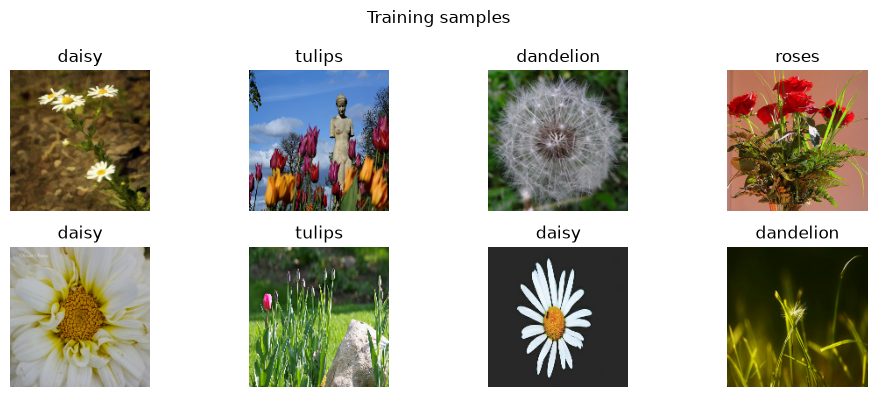

In [4]:
plt.figure(figsize=(10, 4))
for images, labels in train_ds.take(1):
    for i in range(8):
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.suptitle("Training samples")
plt.tight_layout()
plt.show()

## 3. Model - MobileNetV2 with a custom classification head

In [5]:
base = keras.applications.MobileNetV2(
    input_shape=IMG + (3,), include_top=False, weights="imagenet"
)
base.trainable = False

inputs = keras.Input(shape=IMG + (3,))
x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.1)(x)
x = layers.RandomZoom(0.1)(x)
x = keras.applications.mobilenet_v2.preprocess_input(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(num_classes, activation="softmax", dtype="float32")(x)
model = keras.Model(inputs, outputs)

model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
trainable = sum(tf.size(w).numpy() for w in model.trainable_weights)
print(f"Total parameters: {model.count_params():,}")
print(f"Trainable parameters (stage 1): {trainable:,}")

Total parameters: 2,264,389
Trainable parameters (stage 1): 6,405


## 4. Stage 1 - Feature extraction (base frozen)

In [6]:
early_stop_1 = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=2, restore_best_weights=True
)
h1 = model.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS,
    callbacks=[early_stop_1], verbose=2,
)

Epoch 1/5


C:\Users\DELL\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


92/92 - 37s - 402ms/step - accuracy: 0.6492 - loss: 0.9183 - val_accuracy: 0.8065 - val_loss: 0.5440
Epoch 2/5
92/92 - 26s - 284ms/step - accuracy: 0.8355 - loss: 0.4652 - val_accuracy: 0.8283 - val_loss: 0.4651
Epoch 3/5
92/92 - 26s - 280ms/step - accuracy: 0.8573 - loss: 0.3979 - val_accuracy: 0.8420 - val_loss: 0.4383
Epoch 4/5
92/92 - 26s - 286ms/step - accuracy: 0.8822 - loss: 0.3444 - val_accuracy: 0.8529 - val_loss: 0.4097
Epoch 5/5
92/92 - 26s - 286ms/step - accuracy: 0.8873 - loss: 0.3154 - val_accuracy: 0.8597 - val_loss: 0.3833


## 5. Stage 2 - Fine-tuning (top 30 layers, very low learning rate)

In [7]:
base.trainable = True
for layer in base.layers[:-FINE_TUNE_LAYERS]:
    layer.trainable = False
for layer in base.layers[-FINE_TUNE_LAYERS:]:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
trainable = sum(tf.size(w).numpy() for w in model.trainable_weights)
print(f"Trainable parameters (stage 2): {trainable:,}")

early_stop_2 = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=2, restore_best_weights=True
)
h2 = model.fit(
    train_ds, validation_data=val_ds, epochs=FINE_EPOCHS,
    callbacks=[early_stop_2], verbose=2,
)

Trainable parameters (stage 2): 1,517,125
Epoch 1/5
92/92 - 38s - 416ms/step - accuracy: 0.8975 - loss: 0.2826 - val_accuracy: 0.8610 - val_loss: 0.3647
Epoch 2/5
92/92 - 33s - 355ms/step - accuracy: 0.9046 - loss: 0.2464 - val_accuracy: 0.8624 - val_loss: 0.3708
Epoch 3/5
92/92 - 32s - 352ms/step - accuracy: 0.9104 - loss: 0.2388 - val_accuracy: 0.8678 - val_loss: 0.3416
Epoch 4/5
92/92 - 43s - 463ms/step - accuracy: 0.9189 - loss: 0.2147 - val_accuracy: 0.8828 - val_loss: 0.3342
Epoch 5/5
92/92 - 42s - 458ms/step - accuracy: 0.9278 - loss: 0.1977 - val_accuracy: 0.8815 - val_loss: 0.3218


## 6. Evaluation

Validation accuracy: 0.8815  Validation loss: 0.3218


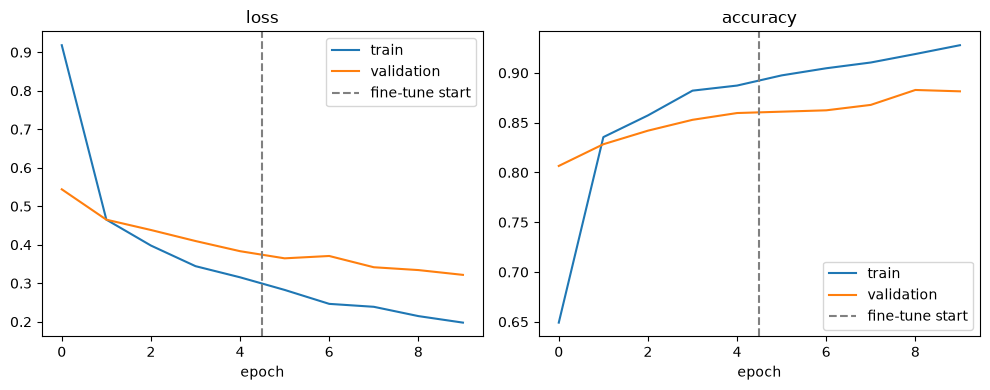

In [8]:
loss, acc = model.evaluate(val_ds, verbose=0)
print(f"Validation accuracy: {acc:.4f}  Validation loss: {loss:.4f}")

hist = {k: h1.history[k] + h2.history[k] for k in h1.history}
n1 = len(h1.history["loss"])
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for i, metric in enumerate(["loss", "accuracy"]):
    ax[i].plot(hist[metric], label="train")
    ax[i].plot(hist["val_" + metric], label="validation")
    ax[i].axvline(n1 - 0.5, color="gray", linestyle="--", label="fine-tune start")
    ax[i].set_title(metric)
    ax[i].set_xlabel("epoch")
    ax[i].legend()
plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

       daisy     0.8972    0.8972    0.8972       107
   dandelion     0.9137    0.9424    0.9278       191
       roses     0.7939    0.8739    0.8320       119
  sunflowers     0.8897    0.8963    0.8930       135
      tulips     0.8957    0.8022    0.8464       182

    accuracy                         0.8815       734
   macro avg     0.8780    0.8824    0.8793       734
weighted avg     0.8830    0.8815    0.8812       734



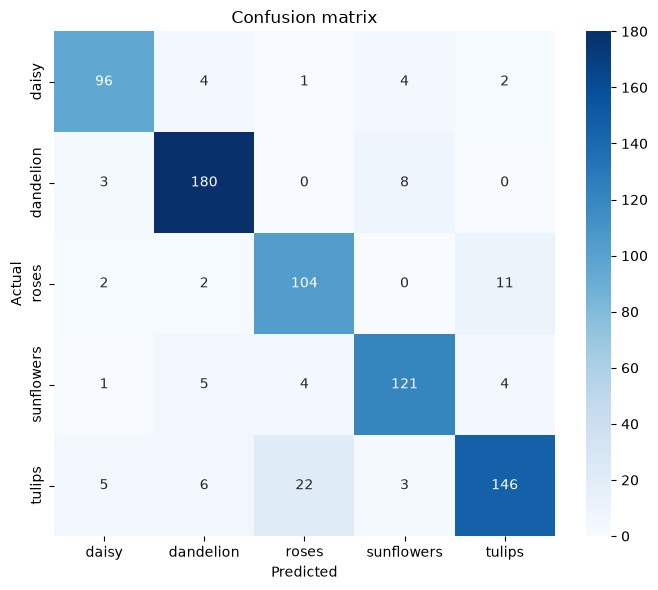

In [9]:
y_true = np.concatenate([labels.numpy() for _, labels in val_ds])
y_pred = model.predict(val_ds, verbose=0).argmax(axis=1)
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

plt.figure(figsize=(7, 6))
sns.heatmap(
    confusion_matrix(y_true, y_pred), annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names, yticklabels=class_names,
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix")
plt.tight_layout()
plt.show()

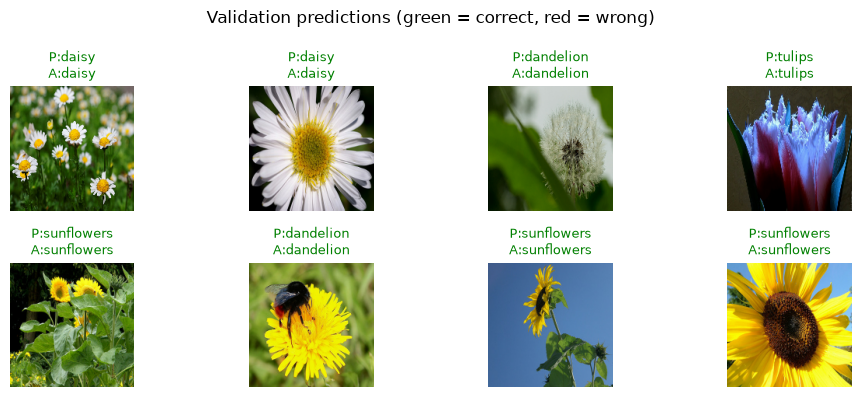

In [10]:
plt.figure(figsize=(10, 4))
for images, labels in val_ds.take(1):
    probs = model.predict(images, verbose=0)
    for i in range(8):
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        p, t = int(probs[i].argmax()), int(labels[i].numpy())
        plt.title(
            f"P:{class_names[p]}\nA:{class_names[t]}",
            color="green" if p == t else "red", fontsize=9,
        )
        plt.axis("off")
plt.suptitle("Validation predictions (green = correct, red = wrong)")
plt.tight_layout()
plt.show()

## 7. Save the model and single-image inference utility

In [11]:
model.save("mobilenetv2_flowers.keras")
print("Saved model to mobilenetv2_flowers.keras")


def predict_image(image_path):
    img = keras.utils.load_img(image_path, target_size=IMG)
    arr = keras.utils.img_to_array(img)[None, ...]
    probs = model.predict(arr, verbose=0)[0]
    plt.imshow(img)
    plt.axis("off")
    plt.title(f"{class_names[probs.argmax()]} ({probs.max():.1%})")
    plt.show()
    return dict(zip(class_names, probs.round(4)))

Saved model to mobilenetv2_flowers.keras
